# 2. Préprocessing et analyse descriptive

**Objectif** : passer de `welddb_processed.csv` (données brutes mises en colonnes) à un jeu de données **propre, numérique et documenté**, puis faire l'analyse descriptive demandée par le sujet (valeurs manquantes, distributions, corrélations, ACP).

Le plan suit le cours *CM0 – Data preprocessing* (valeurs manquantes → outliers → variables catégorielles → mise à l'échelle) et *CM2 – Réduction de dimension* (ACP).

| Étape | Apprend-elle quelque chose des données ? | Où la faire |
|---|---|---|
| 1. Rôle des colonnes (cibles / entrées / à écarter) | Non | Ici, avant tout |
| 2. Nettoyage texte → nombres (`<0.01`, `150-200`, …) | Non (règle fixe ligne par ligne) | Ici, avant le split |
| 3. Analyse des valeurs manquantes + suppression des colonnes trop vides | Très peu (voir remarque) | Ici |
| 4. Outliers (IQR) | Détection seulement | Ici |
| 5. Corrélations, ACP | Oui | Ici **à titre exploratoire** uniquement |
| 6. Imputation, encodage, standardisation | **Oui** | **Dans un `Pipeline`, `fit` sur le train uniquement** |

> Pourquoi cette séparation ? Le cours (CM0, *Transformers* et *Pipelines*) rappelle que `fit` calcule des valeurs (moyenne, médiane…) **sur le train** puis `transform` les applique au test. Si on imputait ou standardisait sur toute la base avant le split, l'information du test « fuirait » dans l'entraînement et les scores seraient trop optimistes (*data leakage*, cf. Kapoor & Narayanan, 2023).

In [1]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid", context="notebook")

# Chemins (pathlib => fonctionne sous Windows, macOS et Linux)
ROOT = Path.cwd().parent
PATH_INTER = ROOT / "1. Données" / "02_intermediate"
PATH_FIG = ROOT / "3. Résultats" / "figures"
PATH_FIG.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(PATH_FIG / f"{name}.png", dpi=150, bbox_inches="tight")

## 0. Chargement

On part du fichier produit par le notebook `1. Traitement de données`. On lit **tout en texte** (`dtype=object`) pour voir les valeurs non numériques avant de les convertir : si on laissait pandas deviner, une colonne contenant `<5` deviendrait entièrement du texte sans qu'on sache pourquoi.

Rappel de la documentation de la base (`welddb.info`) : *« The presence of an "N" indicates that the value was not reported in the publication. This is NOT meant to be an indication that the value is zero. »* → les `N` ont déjà été lus comme `NaN` et **ne doivent pas être remplacés par 0**.

In [2]:
raw = pd.read_csv(PATH_INTER / "welddb_processed.csv", sep=";", dtype=object)
with open(PATH_INTER / "correspondance_between_names_units.json", encoding="utf-8") as f:
    units = json.load(f)

print(raw.shape)
raw.head()

(1652, 44)


,Carbon concentration,Silicon concentration,Manganese concentration,Sulphur concentration,Phosphorus concentration,Nickel concentration,Chromium concentration,Molybdenum concentration,Vanadium concentration,Copper concentration,Cobalt concentration,Tungsten concentration,Oxygen concentration,Titanium concentration,Nitrogen concentration,Aluminium concentration,Boron concentration,Niobium concentration,Tin concentration,Arsenic concentration,Antimony concentration,Current,Voltage,AC or DC,Electrode positive or negative,Heat input,Interpass temperature,Type of weld,Post weld heat treatment temperature,Post weld heat treatment time,Yield strength,Ultimate tensile strength,Elongation,Reduction of Area,Charpy temperature,Charpy impact toughness,Hardness,50 % FATT,Primary ferrite in microstructure,Ferrite with second phase,Acicular ferrite,Martensite,Ferrite with carbide aggreagate,Weld ID
0,0.037,0.3,0.65,0.008,0.012,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,170.0,21.0,DC,+,1.0,200,MMA,250.0,14.0,392.0,466.0,31.9,80.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Aaw
1,0.037,0.3,0.65,0.008,0.012,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,170.0,21.0,DC,+,1.0,200,MMA,0.0,0.0,NaN,NaN,NaN,NaN,-28.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Aawch
2,0.037,0.3,0.65,0.008,0.012,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,170.0,21.0,DC,+,1.0,200,MMA,580.0,2.0,370.0,456.0,35.2,80.6,-38.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Aht
3,0.037,0.31,1.03,0.007,0.014,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,170.0,21.0,DC,+,1.0,200,MMA,250.0,14.0,413.0,498.0,31.2,80.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Evans-Ni/CMn-1990/1991-0Baw
4,0.037,0.31,1.03,0.007,0.014,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,170.0,21.0,DC,+,1.0,200,MMA,0.0,0.0,NaN,NaN,NaN,NaN,-48.0,100.0,NaN,NaN,32,28.0,40.0,0.0,0.0,Evans-Ni/CMn-1990/1991-0Bawch


In [3]:
# Inventaire des valeurs non numériques, colonne par colonne
def non_numeric_values(s):
    s = s.dropna()
    return s[pd.to_numeric(s, errors="coerce").isna()]

inventaire = {
    c: non_numeric_values(raw[c]).value_counts().head(5).to_dict()
    for c in raw.columns
    if len(non_numeric_values(raw[c])) > 0
}
pd.Series(inventaire, name="valeurs non numériques (top 5)").to_frame()

,valeurs non numériques (top 5)
Sulphur concentration,{'<0.002': 7}
Molybdenum concentration,{'<0.01': 2}
Vanadium concentration,"{'<0.0005': 266, '<0.01': 31, '<5': 9, '<0.005..."
Copper concentration,{'<0.01': 14}
Cobalt concentration,{'<0.01': 21}
Tungsten concentration,{'<0.1': 12}
Titanium concentration,"{'<100': 50, '<0.01': 16, '<5': 2, '<10': 2}"
Nitrogen concentration,"{'66totndres': 11, '67tot33res': 7, '61tot34re..."
Aluminium concentration,"{'<5': 343, '<100': 38, '<0.01': 16, '<50': 6}"
Boron concentration,"{'<5': 395, '<10': 24}"


## 1. Rôle des colonnes

Le sujet demande d'**identifier les variables représentatives de la qualité**. Une soudure de bonne qualité doit être à la fois **résistante** (ne pas se déformer ni rompre sous charge) et **tenace** (ne pas casser de façon fragile, notamment à froid). C'est exactement ce que mesurent les essais mécaniques de la base, qui sont d'ailleurs les *keywords* de la documentation : *« yield strength, UTS, elongation, charpy toughness »*.

| Rôle | Colonnes | Justification |
|---|---|---|
| **Cibles** (mesurées *après* soudage) | Yield strength, Ultimate tensile strength, Elongation, Reduction of Area, Charpy impact toughness | Propriétés mécaniques = qualité de la soudure |
| **Condition d'essai** | Charpy temperature | Ce n'est pas une propriété de la soudure mais la température à laquelle l'essai Charpy est fait ; elle sert d'**entrée** pour le modèle de ténacité uniquement |
| **Entrées** (choisies *avant/pendant* le soudage) | Composition chimique, paramètres procédé (courant, tension, AC/DC, polarité, énergie, température entre passes, type de soudure), traitement thermique post-soudage | Ce sont les leviers sur lesquels l'industriel peut agir → utiles pour les recommandations finales |
| **Écartées** | Hardness, 50 % FATT | Cibles possibles mais > 90 % de manquants |
| **Écartées** | 5 colonnes de microstructure | Résultat du soudage (pas un réglage) → les utiliser en entrée serait tricher ; en plus ≈ 94 % de manquants |
| **Identifiant** | Weld ID | Pas une entrée, mais sert à définir la **source bibliographique** (utile pour les manquants et pour une validation croisée groupée) |

In [4]:
TARGETS = [
    "Yield strength",
    "Ultimate tensile strength",
    "Elongation",
    "Reduction of Area",
    "Charpy impact toughness",
]
TEST_CONDITION = ["Charpy temperature"]

CHEMISTRY = [c for c in raw.columns if c.endswith("concentration")]
PROCESS_NUM = ["Current", "Voltage", "Heat input", "Interpass temperature",
               "Post weld heat treatment temperature", "Post weld heat treatment time"]
PROCESS_CAT = ["AC or DC", "Electrode positive or negative", "Type of weld"]

DROPPED_UNUSABLE = ["Hardness", "50 % FATT",
                    "Primary ferrite in microstructure", "Ferrite with second phase",
                    "Acicular ferrite", "Martensite", "Ferrite with carbide aggreagate"]
ID_COL = "Weld ID"

# Vérification : chaque colonne a exactement un rôle
roles = CHEMISTRY + PROCESS_NUM + PROCESS_CAT + TARGETS + TEST_CONDITION + DROPPED_UNUSABLE + [ID_COL]
assert sorted(roles) == sorted(raw.columns), set(raw.columns) ^ set(roles)
print(f"{len(CHEMISTRY)} éléments chimiques, {len(PROCESS_NUM)+len(PROCESS_CAT)} paramètres procédé, {len(TARGETS)} cibles")

21 éléments chimiques, 9 paramètres procédé, 5 cibles


In [5]:
# Source bibliographique = début du Weld ID jusqu'à l'année (ex. 'Evans-AlTi-1994-450/1ch1' -> 'Evans-AlTi-1994')
def source_from_id(weld_id):
    m = re.match(r"^(.*?\d{4})", weld_id)
    return m.group(1) if m else re.split(r"[-/ ]", weld_id)[0]

source = raw[ID_COL].map(source_from_id)
print(f"{source.nunique()} sources distinctes")
source.value_counts().head(10)

148 sources distinctes


Weld ID
Evans-AlTi-1994            114
Evans-StressRelief-1991    110
SvenGret-1990               96
Pat-1981                    79
EvansLetter                 78
Mart                        70
Evans-Nb/Mn-1991            60
Evans-Ti/Mn-1992            60
Evans-V/Mn-1991             60
Evans-Al/CMn-1990           59
Name: count, dtype: int64

## 2. Nettoyage : texte → nombres

Toutes les règles ci-dessous sont **déterministes** (même règle pour chaque ligne, rien n'est appris sur la base) : on peut donc les appliquer avant le split train/test sans fuite d'information.

### 2.a Valeurs sous la limite de détection (`<0.01`, `<5`, …)

`<L` signifie que l'élément a été dosé mais que sa teneur est **entre 0 et L** : l'appareil ne sait pas mesurer en dessous. Trois choix possibles :

| Remplacement | Biais |
|---|---|
| `L` | surestime systématiquement (on prend le pire cas) |
| `0` | sous-estime systématiquement |
| **`L/2`** | milieu de l'intervalle [0 ; L] → convention classique en chimie analytique |

On retient **L/2** (substitution « LOD/2 »). Hornung & Reed (1990) montrent que L/2 est adapté quand les données sont peu asymétriques et proposent L/√2 sinon ; les écarts entre les deux restent négligeables ici car ces valeurs sont très petites devant les teneurs usuelles.
On ajoute aussi une colonne indicatrice `<élément>_below_LOD` pour garder l'information « valeur approximative ».

**Incohérences d'unités repérées** (les unités sont fixes par colonne d'après `welddb.info`) :
- **Vanadium** (en % massique) : 9 valeurs `<5` (source *EvansLetter*). 5 % de V est physiquement impossible dans un métal de soudure (max observé : 0,32 %). La même base contient 266 fois `<0.0005` = 5 ppm → ces `<5` sont très probablement des **ppm** saisis dans une colonne en % → converties en `<0.0005`.
- **Titane et Aluminium** (en ppm) : 16 valeurs `<0.01` (source *PantK-1990*). 0,01 ppm est bien en dessous de toute limite de détection réaliste ; 0,01 % = 100 ppm, et `<100` existe déjà dans ces colonnes → ces valeurs sont très probablement des **%** → converties en `<100`.

In [6]:
df = raw.copy()

# Corrections d'unités (voir justification ci-dessus)
UNIT_FIXES = {
    "Vanadium concentration": {"<5": "<0.0005"},     # ppm saisis dans une colonne en %
    "Titanium concentration": {"<0.01": "<100"},     # % saisis dans une colonne en ppm
    "Aluminium concentration": {"<0.01": "<100"},
}
for col, mapping in UNIT_FIXES.items():
    n = df[col].isin(mapping.keys()).sum()
    df[col] = df[col].replace(mapping)
    print(f"{col:28s} : {n} valeurs corrigées {mapping}")

Vanadium concentration       : 9 valeurs corrigées {'<5': '<0.0005'}
Titanium concentration       : 16 valeurs corrigées {'<0.01': '<100'}
Aluminium concentration      : 16 valeurs corrigées {'<0.01': '<100'}


In [7]:
def parse_detection_limit(s):
    '''`<L` -> L/2 ; renvoie (valeurs numériques, indicateur 0/1 « sous la limite de détection »)'''
    s = s.astype(object)
    below = s.str.startswith("<", na=False)
    values = s.copy()
    values[below] = s[below].str[1:].astype(float) / 2
    return values, below.astype(int)

lod_cols = [c for c in CHEMISTRY if df[c].str.startswith("<", na=False).any()]
for col in lod_cols:
    df[col], indicator = parse_detection_limit(df[col])
    if indicator.sum() >= 30:   # indicateur conservé seulement s'il concerne assez de lignes
        df[col.replace(" concentration", "") + "_below_LOD"] = indicator

pd.Series({c: raw[c].str.startswith("<", na=False).sum() for c in lod_cols}, name="nb valeurs <L").sort_values(ascending=False)

Boron concentration         419
Aluminium concentration     403
Vanadium concentration      308
Niobium concentration       299
Titanium concentration       70
Cobalt concentration         21
Copper concentration         14
Tungsten concentration       12
Arsenic concentration         8
Sulphur concentration         7
Antimony concentration        6
Tin concentration             5
Molybdenum concentration      2
Name: nb valeurs <L, dtype: int64

### 2.b Autres formats

| Colonne | Valeur brute | Règle | Justification |
|---|---|---|---|
| Nitrogen | `67tot33res` | → 67 | La publication donne l'azote **total** (67 ppm) et **résiduel** (33 ppm). Les autres lignes de la colonne sont des teneurs totales → on garde le total pour rester homogène. |
| Interpass temperature | `150-200` | → 175 | Seul intervalle de la base (38 lignes). On prend le milieu. Un encodage en catégorie ferait perdre l'ordre et l'échelle (200 °C > 150 °C) de toute la colonne numérique. |
| Type of weld | `ShMA` | → `MMA` | La doc indique *« ShMA = MMA = manual metal arc »* : même procédé sous deux noms. |
| AC or DC | `DC` / `AC` | → `is_DC` = 1 / 0 | Variable binaire : une seule colonne 0/1 suffit. |
| Electrode positive or negative | `+` / `-` | → `electrode_positive` = 1 / 0 | Idem. |

In [8]:
# Azote : 'XXtotYYres' -> XX (teneur totale)
n_tot = df["Nitrogen concentration"].str.contains("tot", na=False).sum()
df["Nitrogen concentration"] = df["Nitrogen concentration"].str.extract(r"^([\d.]+)", expand=False)
print(f"Azote : {n_tot} valeurs 'tot/res' -> total")

# Intervalle -> milieu
def interval_midpoint(s):
    m = s.str.fullmatch(r"([\d.]+)-([\d.]+)", na=False)
    bounds = s[m].str.split("-", expand=True).astype(float)
    s = s.astype(object).copy()
    s[m] = bounds.mean(axis=1)
    return s

df["Interpass temperature"] = interval_midpoint(df["Interpass temperature"])

# Catégorielles
df["Type of weld"] = df["Type of weld"].replace({"ShMA": "MMA"})
df["is_DC"] = df.pop("AC or DC").map({"DC": 1, "AC": 0})
df["electrode_positive"] = df.pop("Electrode positive or negative").map({"+": 1, "-": 0})
PROCESS_CAT = ["Type of weld"]
PROCESS_BIN = ["is_DC", "electrode_positive"]

df["Type of weld"].value_counts()

Azote : 59 valeurs 'tot/res' -> total


Type of weld
MMA      1180
SA        261
FCA        87
TSA        87
NGSAW      18
NGGMA       7
SAA         4
GMAA        4
GTAA        4
Name: count, dtype: int64

In [9]:
# Conversion finale en numérique + contrôle : aucune valeur ne doit être perdue
num_cols = CHEMISTRY + PROCESS_NUM + TARGETS + TEST_CONDITION
before = df[num_cols].notna().sum()
df = df.drop(columns=DROPPED_UNUSABLE)
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")
lost = before - df[num_cols].notna().sum()
assert lost.sum() == 0, lost[lost > 0]
print("Conversion OK, aucune valeur perdue.", df.shape)

Conversion OK, aucune valeur perdue. (1652, 42)


## 3. Valeurs manquantes

Démarche du cours (CM0, *Dealing with missing values*) :
1. quel est le **pourcentage** de manquants par variable ?
2. **par groupe** de population ?
3. y a-t-il un **prédicteur** des valeurs manquantes ?
→ on en déduit une hypothèse MCAR / MAR / MNAR puis une stratégie.

In [10]:
FEATURES_NUM = CHEMISTRY + PROCESS_NUM
miss = (df[FEATURES_NUM + PROCESS_BIN + TARGETS].isna().mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(7, 9))
colors = ["#c0392b" if c in TARGETS else "#2c7fb8" for c in miss.index]
ax.barh(miss.index, miss.values, color=colors)
for x in (60, 80, 90):
    ax.axvline(x, ls="--", lw=1, color="grey")
ax.set_xlabel("% de valeurs manquantes")
ax.set_title("Valeurs manquantes par variable (rouge = cibles)")
savefig("01_valeurs_manquantes")
plt.show()

<Figure size 700x900 with 1 Axes>

**Par groupe : les manquants dépendent-ils de la source ?**

Pour chaque variable, on regarde, source par source, si elle est *toujours* renseignée, *jamais* renseignée, ou *parfois*. Si la quasi-totalité des sources sont « tout ou rien », c'est que la présence d'une valeur dépend de **la publication** (ce que les auteurs ont choisi de mesurer), pas du hasard.

In [11]:
by_source = df[FEATURES_NUM + TARGETS].isna().groupby(source).mean()
all_or_nothing = ((by_source == 0) | (by_source == 1)).mean() * 100
n_sources_obs = (by_source < 1).sum()

miss_table = pd.DataFrame({
    "% manquant": (df[FEATURES_NUM + TARGETS].isna().mean() * 100).round(1),
    "nb valeurs observées": df[FEATURES_NUM + TARGETS].notna().sum(),
    "nb sources où observée": n_sources_obs,
    "% sources 'tout ou rien'": all_or_nothing.round(0),
}).sort_values("% manquant", ascending=False)
miss_table

,% manquant,nb valeurs observées,nb sources où observée,% sources 'tout ou rien'
Tungsten concentration,95.5,75,26,100.0
Cobalt concentration,92.2,129,27,100.0
Arsenic concentration,85.8,234,8,100.0
Antimony concentration,84.3,260,8,100.0
Tin concentration,82.1,296,10,99.0
Boron concentration,69.5,504,90,99.0
Copper concentration,65.0,578,120,99.0
Nickel concentration,57.8,697,126,99.0
Elongation,57.6,700,86,86.0
Reduction of Area,57.3,705,84,86.0


**Interprétation (hypothèse de mécanisme)**

- Pour les **entrées**, ≈ 99 % des sources sont « tout ou rien » (pour les cibles ≈ 85 %) : la probabilité qu'une valeur manque est presque entièrement expliquée par une variable **observée** (la source / le programme expérimental). C'est la définition du **MAR** du cours : $P(X_j \text{ manquant} \mid X) = P(X_j \text{ manquant} \mid X_{observé})$.
- Ce n'est **pas du MCAR** : les manquants ne tombent pas « par malchance » sur des lignes au hasard.
- Une part de **MNAR** est plausible pour les éléments en traces (un laboratoire ne dose pas un élément qu'il n'a pas ajouté volontairement, donc probablement faible). Mais la documentation précise explicitement que « N » ne veut pas dire 0 : on ne peut pas le prouver, et le cours indique qu'*« en l'absence de preuve contraire, il est raisonnable de supposer MAR »*.

**Conséquences sur la stratégie**
- *Listwise deletion* (supprimer les lignes incomplètes) : à éviter, le cours la déconseille en MAR/MNAR, et ici elle ne laisserait presque aucune ligne.
- **Supprimer les colonnes** observées sur trop peu de lignes **et** trop peu de sources : une imputation n'y serait qu'une extrapolation depuis 2-3 publications.
- **Imputer** les autres, dans le pipeline (section 6), avec un **indicateur de manquant** : puisque « manquant » dépend de la source, cette information peut elle-même être prédictive.

In [12]:
# Seuil de suppression des ENTRÉES (jamais des cibles)
SEUIL_NAN = 0.80

feat_miss = df[FEATURES_NUM].isna().mean()
DROPPED_SPARSE = feat_miss[feat_miss > SEUIL_NAN].index.tolist()

print(f"Seuil = {SEUIL_NAN:.0%} -> colonnes supprimées :")
display(miss_table.loc[DROPPED_SPARSE, ["% manquant", "nb valeurs observées", "nb sources où observée"]])

for s in (0.6, 0.7, 0.8, 0.9):
    print(f"  seuil {s:.0%} : supprimerait {feat_miss[feat_miss > s].index.str.replace(' concentration','').tolist()}")

Seuil = 80% -> colonnes supprimées :


,% manquant,nb valeurs observées,nb sources où observée
Cobalt concentration,92.2,129,27
Tungsten concentration,95.5,75,26
Tin concentration,82.1,296,10
Arsenic concentration,85.8,234,8
Antimony concentration,84.3,260,8


  seuil 60% : supprimerait ['Copper', 'Cobalt', 'Tungsten', 'Boron', 'Tin', 'Arsenic', 'Antimony']
  seuil 70% : supprimerait ['Cobalt', 'Tungsten', 'Tin', 'Arsenic', 'Antimony']
  seuil 80% : supprimerait ['Cobalt', 'Tungsten', 'Tin', 'Arsenic', 'Antimony']
  seuil 90% : supprimerait ['Cobalt', 'Tungsten']


**Choix du seuil : 80 %.** Le cours souligne qu'un seuil universel n'existe pas ; on le justifie donc par les données :
- au-dessus de 80 % (W, Co, As, Sb, Sn), chaque variable n'est observée que sur **≈ 70 à 300 lignes issues de très peu de sources** → l'imputation reposerait sur quelques publications seulement ;
- le **bore** (≈ 70 %) est conservé : il est connu en métallurgie pour avoir un effet fort sur la ténacité même à quelques ppm (il retarde la formation de ferrite aux joints de grains et favorise la ferrite aciculaire), et il est observé sur plus de 500 lignes ;
- un seuil à 60 % (proposé dans l'équipe) supprimerait aussi B et Cu, ce qui paraît trop agressif pour des éléments métallurgiquement actifs. **À discuter en équipe** : la cellule ci-dessus montre l'effet de chaque seuil.

> Remarque de rigueur : ce seuil est calculé sur toute la base, avant le split. C'est une très légère fuite d'information, négligeable ici (la décision serait identique sur 80 % des lignes).

In [13]:
df = df.drop(columns=DROPPED_SPARSE)
df = df.drop(columns=[c for c in df.columns if c.endswith("_below_LOD")
                      and c.replace("_below_LOD", " concentration") in DROPPED_SPARSE])
CHEMISTRY = [c for c in CHEMISTRY if c not in DROPPED_SPARSE]
FEATURES_NUM = CHEMISTRY + PROCESS_NUM
LOD_FLAGS = [c for c in df.columns if c.endswith("_below_LOD")]
print(f"Entrées numériques : {len(FEATURES_NUM)}, indicateurs LOD : {LOD_FLAGS}")

Entrées numériques : 22, indicateurs LOD : ['Vanadium_below_LOD', 'Titanium_below_LOD', 'Aluminium_below_LOD', 'Boron_below_LOD', 'Niobium_below_LOD']


**Les cibles** : combien de lignes pour chaque cible, et combien ont **toutes** les cibles ? C'est ce qui détermine la stratégie « un modèle par cible » et l'intérêt du semi-supervisé.

Yield strength               780
Ultimate tensile strength    738
Elongation                   700
Reduction of Area            705
Charpy impact toughness      879

Lignes avec au moins une cible : 1547
Lignes avec toutes les cibles  : 134
Lignes sans aucune cible       : 105


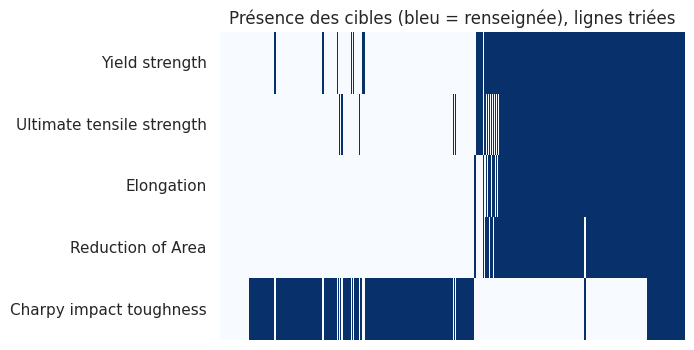

In [14]:
target_counts = df[TARGETS].notna().sum().rename("nb lignes étiquetées")
print(target_counts.to_string())
print(f"\nLignes avec au moins une cible : {df[TARGETS].notna().any(axis=1).sum()}")
print(f"Lignes avec toutes les cibles  : {df[TARGETS].notna().all(axis=1).sum()}")
print(f"Lignes sans aucune cible       : {df[TARGETS].isna().all(axis=1).sum()}")

plt.figure(figsize=(6, 4))
sns.heatmap(df[TARGETS].notna().T.astype(int).loc[:, df[TARGETS].notna().sum(axis=1).sort_values().index],
            cbar=False, cmap="Blues", xticklabels=False)
plt.title("Présence des cibles (bleu = renseignée), lignes triées")
savefig("02_presence_cibles")
plt.show()

## 4. Outliers (méthode IQR du cours)

Méthode de Tukey (1977) vue en CM0 : une valeur est atypique si elle est hors de $[Q_1 - 1.5\,IQR \; ; \; Q_3 + 1.5\,IQR]$.

Le cours distingue deux cas : **erreur de mesure** (→ traiter comme une valeur manquante) ou **situation extraordinaire** (→ garder). Ici, beaucoup de « outliers » statistiques sont des **aciers volontairement alliés** (ex. soudures 9Cr-1Mo avec ~9 % de chrome) ou des traitements thermiques particuliers : ce sont des cas réels, pas des erreurs. On **détecte sans supprimer**, et on vérifie seulement les valeurs physiquement impossibles.

In [15]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out = pd.DataFrame({
    "nb outliers IQR": df[FEATURES_NUM + TARGETS].apply(iqr_outliers),
    "min": df[FEATURES_NUM + TARGETS].min(),
    "médiane": df[FEATURES_NUM + TARGETS].median(),
    "max": df[FEATURES_NUM + TARGETS].max(),
    "unité": [units.get(c, "") for c in FEATURES_NUM + TARGETS],
}).sort_values("nb outliers IQR", ascending=False)
out

,nb outliers IQR,min,médiane,max,unité
Interpass temperature,588,20.000,200.000,300.00,deg C
Current,310,115.000,170.000,900.00,A
Nitrogen concentration,172,21.000,82.000,552.00,parts per million by weight
Vanadium concentration,171,0.000,0.005,0.32,(weight%)
Heat input,161,0.600,1.000,7.90,kJ/mm
Oxygen concentration,156,132.000,423.000,1650.00,parts per million by weight
Silicon concentration,153,0.040,0.320,1.14,(weight%)
Sulphur concentration,126,0.001,0.007,0.14,(weight%)
Nickel concentration,126,0.000,0.067,3.50,(weight%)
Chromium concentration,120,0.000,0.530,10.20,(weight%)


In [16]:
# Contrôles de cohérence physique (valeurs impossibles = erreurs)
checks = {
    "concentration négative": (df[CHEMISTRY] < 0).any(axis=1),
    "UTS < limite d'élasticité": df["Ultimate tensile strength"] < df["Yield strength"],
    "pourcentage > 100": (df[["Elongation", "Reduction of Area"]] > 100).any(axis=1),
}
pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="nb lignes")

concentration négative       0
UTS < limite d'élasticité    0
pourcentage > 100            0
Name: nb lignes, dtype: int64

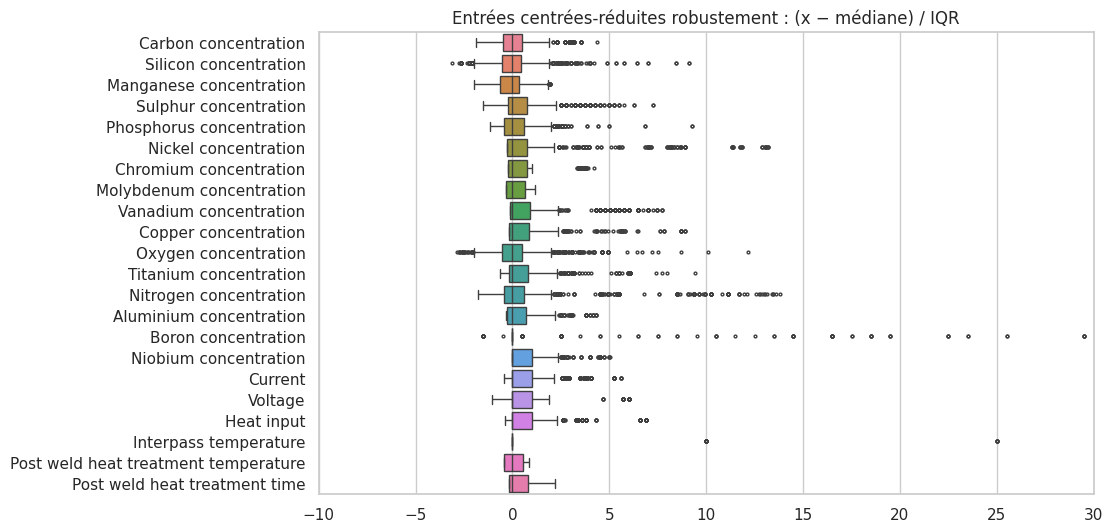

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))
z = (df[FEATURES_NUM] - df[FEATURES_NUM].median()) / (df[FEATURES_NUM].quantile(.75) - df[FEATURES_NUM].quantile(.25)).replace(0, 1)
sns.boxplot(data=z, orient="h", ax=ax, fliersize=2)
ax.set_xlim(-10, 30)
ax.set_title("Entrées centrées-réduites robustement : (x − médiane) / IQR")
savefig("03_boxplots_entrees")
plt.show()

## 5. Analyse descriptive

### 5.a Distribution des cibles

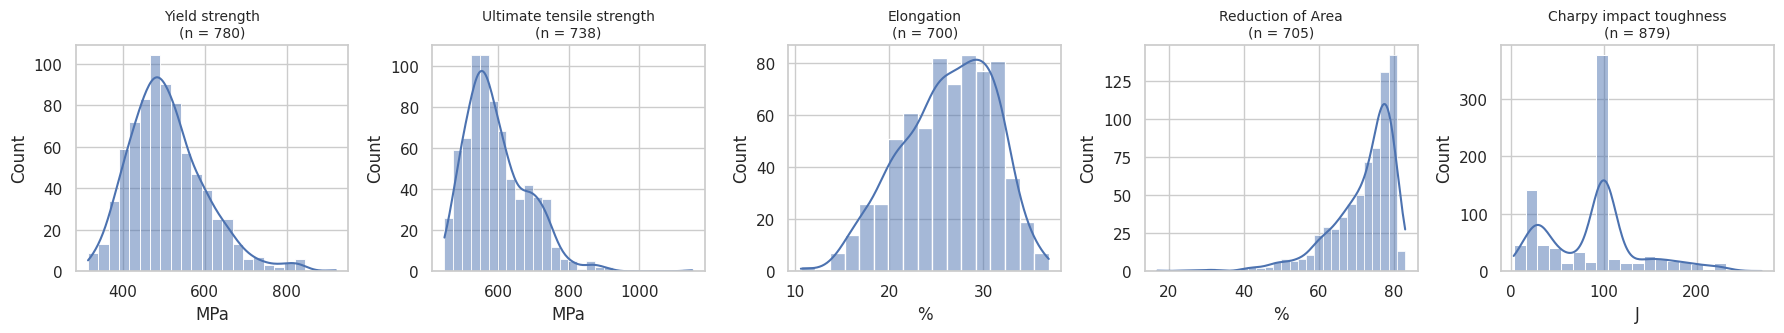

,count,mean,std,min,25%,50%,75%,max
Yield strength,780.0,508.6,92.9,315.0,443.0,495.0,559.2,920.0
Ultimate tensile strength,738.0,594.4,88.6,447.0,532.8,575.5,647.0,1151.0
Elongation,700.0,26.3,4.9,10.6,22.8,26.8,30.0,37.0
Reduction of Area,705.0,71.8,8.9,17.0,68.0,75.0,78.0,83.0
Charpy impact toughness,879.0,87.7,50.1,3.0,38.0,100.0,100.0,270.0


In [18]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(18, 3.5))
for ax, t in zip(axes, TARGETS):
    sns.histplot(df[t].dropna(), ax=ax, kde=True)
    ax.set_title(f"{t}\n(n = {df[t].notna().sum()})", fontsize=10)
    ax.set_xlabel(units.get(t, ""))
plt.tight_layout()
savefig("04_distribution_cibles")
plt.show()

df[TARGETS].describe().T.round(1)

**⚠️ Point important sur la ténacité Charpy**

La distribution de `Charpy impact toughness` a deux pics anormaux : **356 valeurs valent exactement 100 J et 118 exactement 28 J**, alors que la température d'essai correspondante varie beaucoup (de −85 °C à +59 °C). Ce n'est pas un hasard : dans beaucoup de publications (notamment la série *Evans*), on ne rapporte pas « l'énergie mesurée à une température donnée » mais **« la température à laquelle la soudure atteint 100 J (ou 28 J) »** — les températures de transition classiques T₁₀₀J et T₂₈J.

Conséquence : pour ces lignes, l'information est dans `Charpy temperature`, pas dans `Charpy impact toughness`. Prédire directement l'énergie Charpy mélangerait deux types de mesure. **Options à discuter en équipe** :
1. garder l'énergie comme cible et la température comme entrée (simple, mais le modèle apprendra surtout « 100 J » par cœur) ;
2. **prédire la température de transition T₁₀₀J** sur les lignes où l'énergie vaut 100 J (cible plus homogène et plus parlante pour un industriel : plus T₁₀₀J est basse, plus la soudure reste tenace à froid) ;
3. transformer en classification : « tenace / fragile » selon que l'énergie dépasse un seuil à une température donnée.

356 valeurs à 100 J et 118 à 28 J sur 879 valeurs Charpy


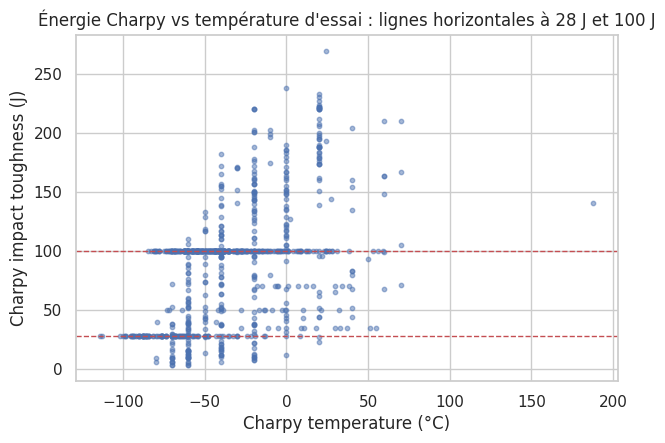

In [19]:
c = df["Charpy impact toughness"]
print(f"{(c == 100).sum()} valeurs à 100 J et {(c == 28).sum()} à 28 J sur {c.notna().sum()} valeurs Charpy")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(df["Charpy temperature"], c, s=10, alpha=.5)
for level in (28, 100):
    ax.axhline(level, ls="--", color="C3", lw=1)
ax.set_xlabel("Charpy temperature (°C)"); ax.set_ylabel("Charpy impact toughness (J)")
ax.set_title("Énergie Charpy vs température d'essai : lignes horizontales à 28 J et 100 J")
savefig("04b_charpy_28J_100J")
plt.show()

### 5.b Corrélations

On utilise la corrélation de **Spearman** (sur les rangs) plutôt que Pearson : elle capte les relations monotones non linéaires et est peu sensible aux outliers relevés en section 4. Chaque coefficient est calculé sur les paires de valeurs disponibles (*pairwise*) : les coefficients reposent donc sur des effectifs différents, à garder en tête pour l'interprétation.

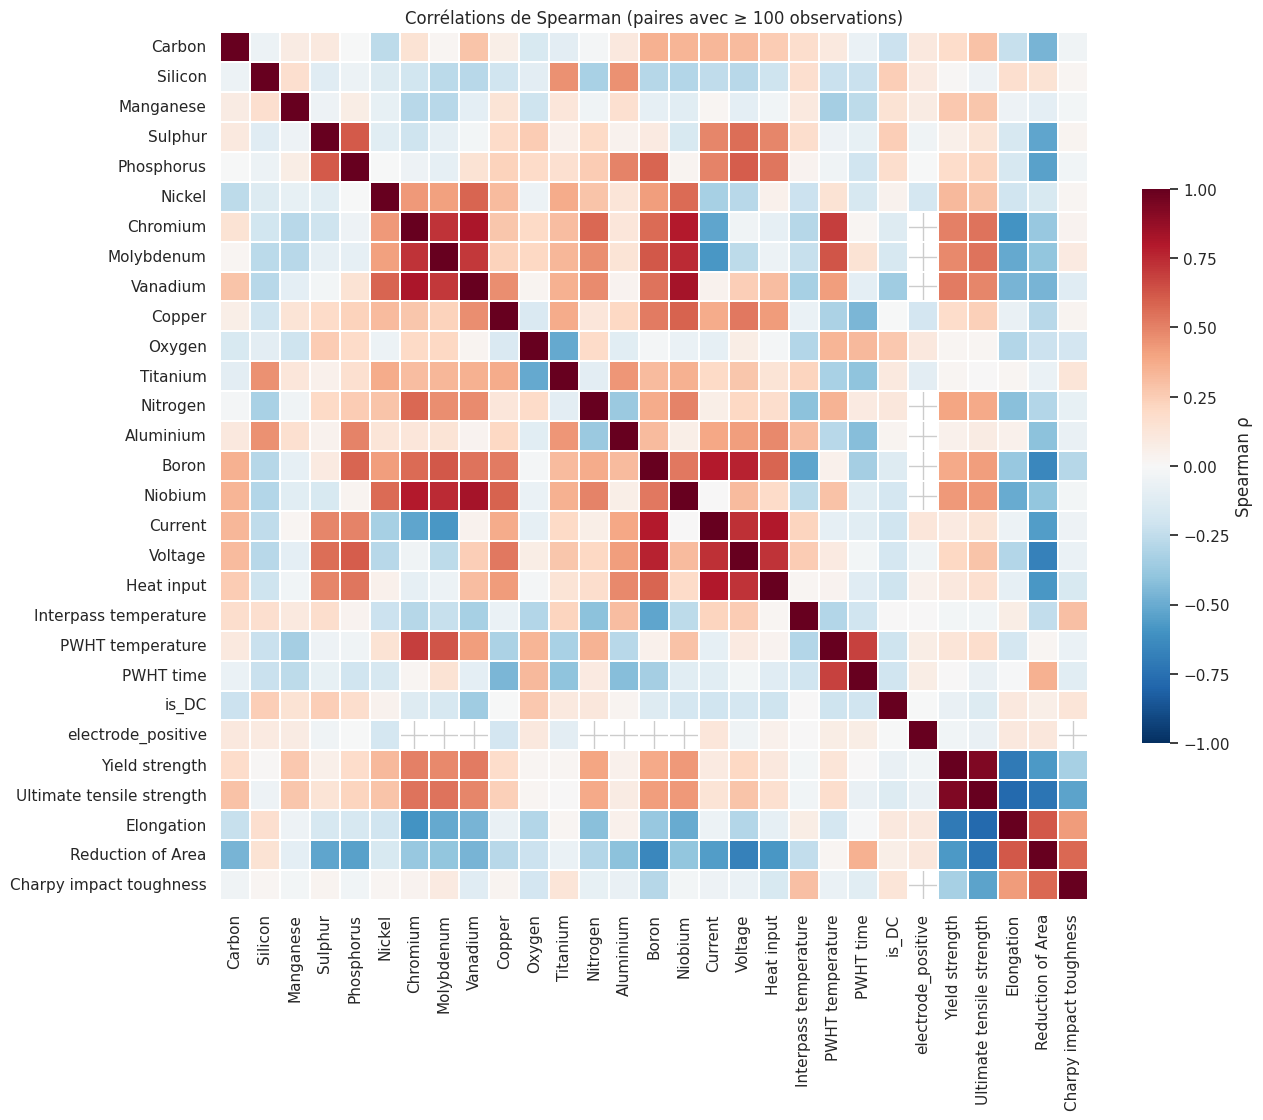

In [20]:
corr = df[FEATURES_NUM + PROCESS_BIN + TARGETS].corr(method="spearman", min_periods=100)
short = lambda c: c.replace(" concentration", "").replace("Post weld heat treatment", "PWHT")
corr = corr.rename(index=short, columns=short)

plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=.3,
            cbar_kws={"shrink": .6, "label": "Spearman ρ"})
plt.title("Corrélations de Spearman (paires avec ≥ 100 observations)")
savefig("05_correlations")
plt.show()

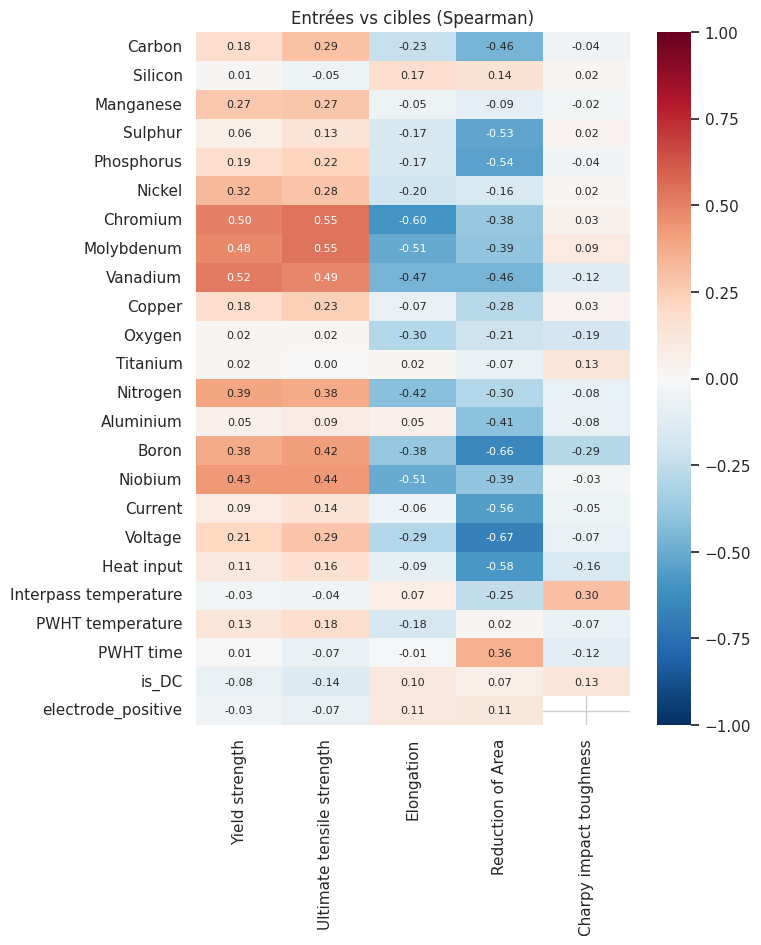

In [21]:
# Corrélation de chaque entrée avec chaque cible
corr_targets = corr.loc[[short(c) for c in FEATURES_NUM + PROCESS_BIN], [short(t) for t in TARGETS]]
plt.figure(figsize=(7, 9))
sns.heatmap(corr_targets, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title("Entrées vs cibles (Spearman)")
savefig("06_correlations_cibles")
plt.show()

### 5.c Analyse en Composantes Principales (CM2)

**But** : développer de l'intuition sur la structure des **entrées** (le sujet le demande explicitement) : quelles variables varient ensemble, y a-t-il des groupes de soudures, des individus atypiques ?

Choix (cours CM2) :
- ACP sur les **entrées uniquement** (non supervisée ; les cibles serviront juste à colorer les points) ;
- variables **standardisées** : sinon les variables en ppm ou en °C (grandes variances) domineraient celles en % massique (cf. l'exemple *USArrests* du cours, où `Assault` écrase tout sans standardisation) ;
- **imputation par la médiane** avant l'ACP, uniquement pour cette exploration (l'ACP ne gère pas les NaN). Elle écrase la variance des variables très manquantes : à mentionner dans le rapport comme limite.
- nombre de composantes : règle des **80 % de variance cumulée**, **coude** de l'histogramme, **critère de Kaiser** (λ > 1 sur données centrées-réduites).

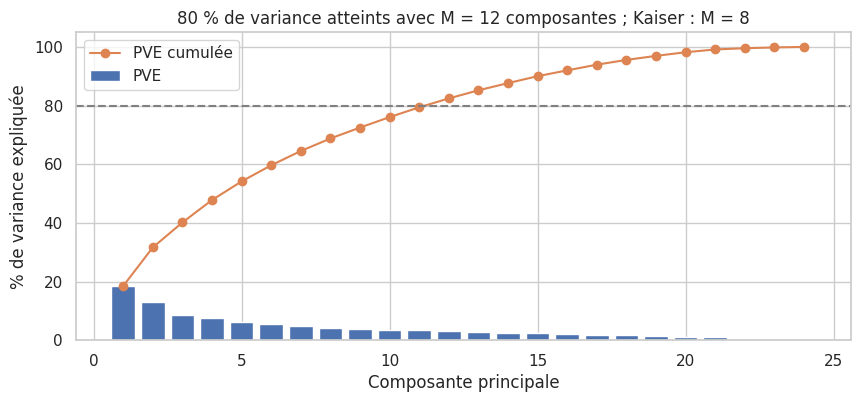

In [22]:
X_pca_in = df[FEATURES_NUM + PROCESS_BIN]
pca_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("pca", PCA()),
])
scores = pca_pipe.fit_transform(X_pca_in)
pca = pca_pipe.named_steps["pca"]
pve = pca.explained_variance_ratio_
eig = pca.explained_variance_

M80 = int(np.argmax(np.cumsum(pve) >= 0.80) + 1)
M_kaiser = int((eig > 1).sum())

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(1, len(pve) + 1), pve * 100, label="PVE")
ax.plot(range(1, len(pve) + 1), np.cumsum(pve) * 100, "o-", color="C1", label="PVE cumulée")
ax.axhline(80, ls="--", color="grey")
ax.set_xlabel("Composante principale"); ax.set_ylabel("% de variance expliquée")
ax.set_title(f"80 % de variance atteints avec M = {M80} composantes ; Kaiser : M = {M_kaiser}")
ax.legend()
savefig("07_acp_variance")
plt.show()

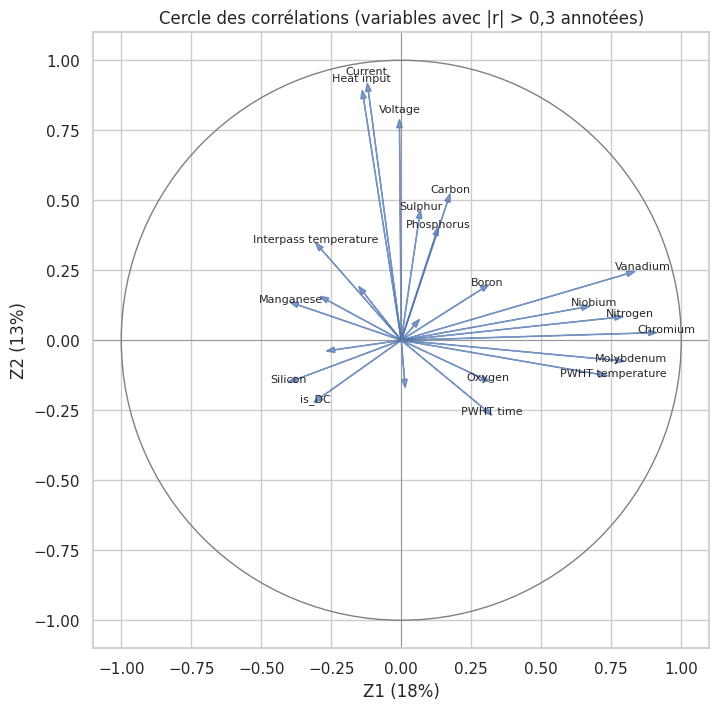

In [23]:
# Cercle des corrélations Z1/Z2 : corr(Z_m, X_j)
X_std = pca_pipe[:-1].transform(X_pca_in)
circle = pd.DataFrame(
    [[np.corrcoef(X_std[:, j], scores[:, m])[0, 1] for m in (0, 1)] for j in range(X_std.shape[1])],
    index=[short(c) for c in X_pca_in.columns], columns=["Z1", "Z2"])

fig, ax = plt.subplots(figsize=(8, 8))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
for name, (x, y) in circle.iterrows():
    ax.arrow(0, 0, x, y, head_width=0.02, color="C0", alpha=.7)
    if np.hypot(x, y) > 0.3:
        ax.text(x * 1.07, y * 1.07, name, fontsize=8, ha="center")
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
ax.axhline(0, color="grey", lw=.5); ax.axvline(0, color="grey", lw=.5)
ax.set_xlabel(f"Z1 ({pve[0]:.0%})"); ax.set_ylabel(f"Z2 ({pve[1]:.0%})")
ax.set_title("Cercle des corrélations (variables avec |r| > 0,3 annotées)")
savefig("08_acp_cercle")
plt.show()

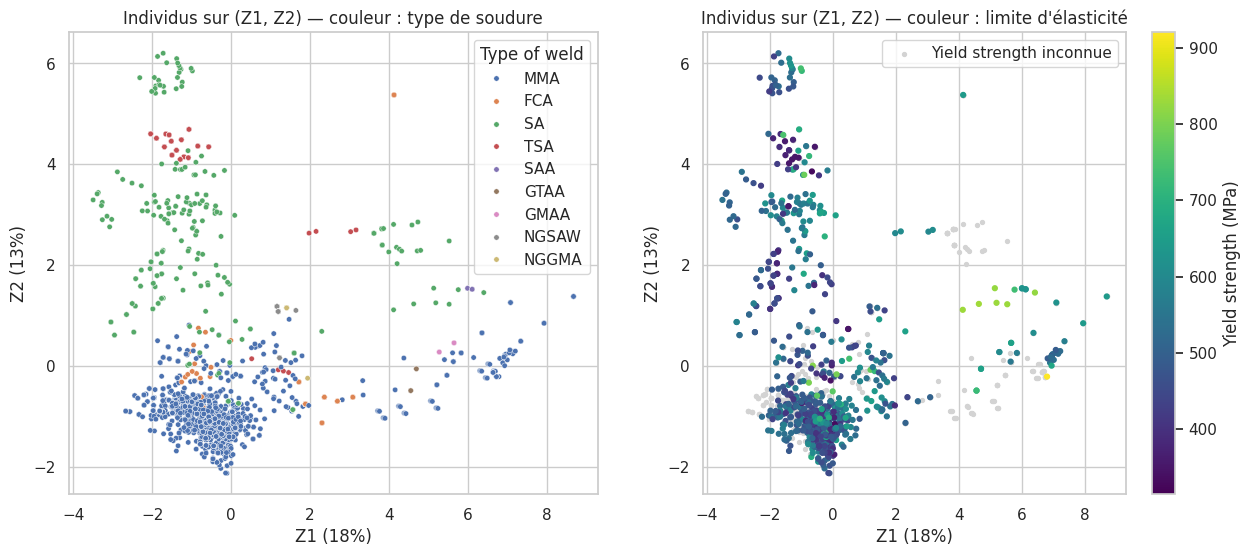

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(x=scores[:, 0], y=scores[:, 1], hue=df["Type of weld"], s=15, ax=axes[0])
axes[0].set_title("Individus sur (Z1, Z2) — couleur : type de soudure")

lab = df["Yield strength"].notna()
axes[1].scatter(scores[~lab, 0], scores[~lab, 1], s=8, c="lightgrey", label="Yield strength inconnue")
sc = axes[1].scatter(scores[lab, 0], scores[lab, 1], s=12, c=df.loc[lab, "Yield strength"], cmap="viridis")
plt.colorbar(sc, ax=axes[1], label="Yield strength (MPa)")
axes[1].legend(loc="upper right"); axes[1].set_title("Individus sur (Z1, Z2) — couleur : limite d'élasticité")
for ax in axes:
    ax.set_xlabel(f"Z1 ({pve[0]:.0%})"); ax.set_ylabel(f"Z2 ({pve[1]:.0%})")
savefig("09_acp_individus")
plt.show()

**Pistes d'interprétation à compléter après exécution** (à reformuler avec vos propres graphiques) :
- quelles variables contribuent le plus à Z1 et Z2 (flèches longues sur le cercle) ? des éléments d'alliage qui vont ensemble (ex. Cr–Mo pour les aciers résistants au fluage) ?
- les types de soudure forment-ils des groupes séparés ? → si oui, le type de soudure est une variable structurante ;
- les lignes **sans** cible (gris) occupent-elles la même zone que les lignes étiquetées ? → si oui, c'est un bon signe pour le **semi-supervisé** (les données non étiquetées ressemblent aux étiquetées) ; sinon, le semi-supervisé risque d'extrapoler.
- le % de variance de (Z1, Z2) est-il suffisant pour que la projection soit fiable (cours : *« la représentation n'est valide que si le % de variance expliquée par Z1 et Z2 est suffisamment grand »*) ?

## 6. Préprocesseur pour la modélisation (à utiliser dans un `Pipeline`)

Tout ce qui **apprend** des données est regroupé ici, pour être `fit` **sur le train uniquement** (cours CM0, *Pipelines*).

| Bloc | Transformation | Justification |
|---|---|---|
| Entrées numériques | Imputation + **indicateur de manquant** (`add_indicator=True`) puis `StandardScaler` | MAR → imputation ; l'indicateur garde l'information « non mesuré dans cette publication ». Standardisation (moyenne 0, écart-type 1) plutôt que min-max, moins sensible aux outliers (cours) — inutile pour les arbres, indispensable pour KNN, SVR, régressions pénalisées. |
| Binaires (`is_DC`, `electrode_positive`) | Mode | Peu de manquants (9-13 %), variable 0/1 |
| Type de soudure | `OneHotEncoder(drop="first")` | Variable **nominale** → one-hot ; `drop="first"` supprime la multicolinéarité (somme des dummies = 1) signalée dans le cours |

**Deux imputeurs au choix, à comparer en validation croisée :**
- `SimpleImputer(strategy="median")` : imputation **univariée**, robuste aux outliers (baseline simple) ;
- `IterativeImputer(sample_posterior=True)` : imputation **multivariée** ; c'est la *stochastic regression imputation* du cours (chaque variable est prédite à partir des autres **plus un bruit**), qui **préserve les corrélations** au lieu de les renforcer (van Buuren, 2018).

> La cible n'est pas utilisée pour imputer les entrées : au moment de prédire une nouvelle soudure, on ne la connaît pas.

In [25]:
def make_preprocessor(numeric_features, imputer="median"):
    num_imputer = (SimpleImputer(strategy="median", add_indicator=True) if imputer == "median"
                   else IterativeImputer(sample_posterior=True, max_iter=20, random_state=0, add_indicator=True))
    return ColumnTransformer([
        ("num", Pipeline([("impute", num_imputer), ("scale", StandardScaler())]), numeric_features),
        ("bin", SimpleImputer(strategy="most_frequent"), PROCESS_BIN + LOD_FLAGS),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), PROCESS_CAT),
    ])

# Exemple : entrées pour chaque cible (la température Charpy seulement pour la ténacité)
FEATURES_BY_TARGET = {t: FEATURES_NUM + (TEST_CONDITION if t == "Charpy impact toughness" else []) for t in TARGETS}

# Test rapide sur la cible Yield strength
t = "Yield strength"
d = df[df[t].notna()]
pre = make_preprocessor(FEATURES_BY_TARGET[t], imputer="iterative")
Xt = pre.fit_transform(d)
print(f"{t} : {d.shape[0]} lignes -> matrice {Xt.shape}, NaN restants : {np.isnan(Xt).sum()}")

Yield strength : 780 lignes -> matrice (780, 54), NaN restants : 0


## 7. Sauvegarde

On sauvegarde le jeu **nettoyé mais non imputé ni standardisé** (ces étapes se font dans le pipeline), ainsi que le rôle des colonnes pour les notebooks de modélisation.

In [26]:
df_out = df.copy()
df_out["source"] = source
df_out.to_csv(PATH_INTER / "welddb_clean.csv", sep=";", index=False)

column_roles = {
    "targets": TARGETS,
    "test_condition": TEST_CONDITION,
    "features_numeric": FEATURES_NUM,
    "features_binary": PROCESS_BIN + LOD_FLAGS,
    "features_categorical": PROCESS_CAT,
    "id": ID_COL,
    "group": "source",
    "dropped_unusable": DROPPED_UNUSABLE,
    "dropped_sparse": DROPPED_SPARSE,
    "nan_threshold": SEUIL_NAN,
}
with open(PATH_INTER / "column_roles.json", "w", encoding="utf-8") as f:
    json.dump(column_roles, f, indent=4, ensure_ascii=False)

print(df_out.shape, "->", PATH_INTER / "welddb_clean.csv")

(1652, 38) -> /tmp/claude-0/proj/1. Données/02_intermediate/welddb_clean.csv


## Références

**Cours**
- M. Tami, *CM0 – Introduction and Prerequisites to Machine Learning* (sections *Data preprocessing* et *Scikit-learn: a tour*), CentraleSupélec.
- M. Tami, *CM2 – Dimensionality Reduction* (section *PCA*), CentraleSupélec.

**Données**
- T. Cool, H. K. D. H. Bhadeshia, D. J. C. MacKay (1997). *The yield and ultimate tensile strength of steel welds*. Materials Science and Engineering A, 223, 186-200. — publication d'origine de la base.
- Documentation de la base : [MAP_DATA_WELD, University of Cambridge](https://www.phase-trans.msm.cam.ac.uk/map/data/materials/welddb-b.html)

**Valeurs manquantes**
- D. B. Rubin (1976). *Inference and missing data*. Biometrika, 63(3), 581-592. [doi:10.1093/biomet/63.3.581](https://doi.org/10.1093/biomet/63.3.581) — définition de MCAR / MAR / MNAR.
- J. L. Schafer, J. W. Graham (2002). *Missing data: our view of the state of the art*. Psychological Methods, 7(2), 147-177. [doi:10.1037/1082-989X.7.2.147](https://doi.org/10.1037/1082-989X.7.2.147) — cité dans le cours.
- S. van Buuren (2018). *Flexible Imputation of Missing Data*, 2nd ed., CRC Press. [En ligne](https://stefvanbuuren.name/fimd/) — cité dans le cours ; imputation stochastique / multiple.
- [scikit-learn User Guide – Imputation of missing values](https://scikit-learn.org/stable/modules/impute.html)

**Limites de détection**
- R. W. Hornung, L. D. Reed (1990). *Estimation of average concentration in the presence of nondetectable values*. Applied Occupational and Environmental Hygiene, 5(1), 46-51. [doi:10.1080/1047322X.1990.10389587](https://doi.org/10.1080/1047322X.1990.10389587) — substitution L/2 et L/√2.

**Outliers, ACP, fuite de données**
- J. W. Tukey (1977). *Exploratory Data Analysis*. Addison-Wesley — règle 1,5 × IQR.
- I. T. Jolliffe, J. Cadima (2016). *Principal component analysis: a review and recent developments*. Phil. Trans. R. Soc. A, 374, 20150202. [doi:10.1098/rsta.2015.0202](https://doi.org/10.1098/rsta.2015.0202)
- S. Kapoor, A. Narayanan (2023). *Leakage and the reproducibility crisis in machine-learning-based science*. Patterns, 4(9), 100804. [doi:10.1016/j.patter.2023.100804](https://doi.org/10.1016/j.patter.2023.100804)